### **Student Information**
GitHub ID:kerwin77106

Kaggle name:kerwin77106

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

**(1) 資料概況**

- 訓練集3360筆、測試集1440筆
- 類別分布：joy 26% anger 20.1% sadness 18.7% disgust 13.5% surprise 13.1% fear 8.6%。最少的 fear 只有 joy 的33% 類別不平衡
- 因此我使用 macro F1 來評分 都各自算F1最後再直接平均，讓少數和多數一樣重要

**(2) 資料特性的發現**

- 我發現它們來自 reddit留言 和 翻譯出來的句子
- 另外有發現重複句與標籤不一致的問題，同一句話被標成不同情緒

**(3) 文字清理**

- 主要給 TF-IDF 用的清理，文字清理我把引號統一，拉長字縮短，並加上標記，因為覺得拉長字通常帶有情緒線索，並把NAME換成personname 避免被當成一般文字，全部轉小寫等等

**(4) 重複句處理與驗證切分**

- 我嘗試使用全部保留，把不一致的問句整組刪除，每個文字只留一筆取多數的標籤，或是每個文字加標籤的組合只留一筆
- 測試下來結果差距大約只有 +-0.0005差異，所以最後還是決定用全部保留來訓練，因為無法判斷哪個標籤才是正確的
- 一開始只用80/20來切分，但發現出來的分數跟 kaggle public會有較大落差，單一切分分數有0.631 但public只有 0.600
- 當改用五折後，誤差縮小很多，原本誤差約在0.014～0.033之間 改用五折後誤差縮小到 0.005，可以方便我更精準估算分數

---

### 1.2 Feature Engineering Steps

**(1) TF-IDF（字詞＋字元 n-gram）**

- 設定：我們同時使用兩種切法 字詞漢字元特徵去切，分類器是用logistic Regression
- 實驗顯示真正有影響的是字詞和字元特徵合併和類別權重，其他調整都在雜訊內。
- 限制：不考慮順序，在bag裡完全相同，沒有語意，結果單獨分數遠低於 transformer,但有另外發現他的錯誤型態和模型不同，放進融合有幫助

**(2) 試過但放棄的特徵：預訓練句向量**

| 做法 | 分數 |
|---|---|
| all-MiniLM-L6-v2 句向量 + LR（單一切分） | 0.4908～0.4978 |
| all-mpnet-base-v2 句向量（平均池化）+ LR（單一切分） | 0.4981～0.5055 |
| all-mpnet-base-v2 + LR（5 折 OOF） | 0.4902 |
| 把 mpnet 加進融合（巢狀驗證） | 0.6067 → 0.6073，幾乎沒幫助 |

**(3) Transformer 的上下文表示**

原始文字 → 切詞器（tokenizer）切成子詞 → 查表得到每個子詞的向量 → 24 層自注意力 → 句首 `<s>` 位置的向量 → 分類頭 → 6 類分數

- 最後選擇twitter-roberta-large-2022-154m（G3b） 效果最好，deberta-v3-large在我電腦跑不動..直接當掉
- 選擇原因是因為社群媒體預訓練的模型對口語、縮寫、表情符號的表示更貼近這份資料

**(4) 大型語言模型的指令式輸入**

```
Classify the emotion expressed in this social media post as one of: anger, disgust, fear, joy, sadness, surprise.
Post: {post}
Emotion:
```

- 一開始是使用原文直接輸入，最後OOF指得到 0.5944左右
- 改用這個指令輸入後 OOF提升到0.6292
- 關鍵是把 emotion放在最後面，讓向量有最多情緒的資訊

**(5) 比較**

| 表示方式 | 代表模型 | 單一模型 OOF | 翻譯部分 OOF |
|---|---|---|---|
| TF-IDF 字詞＋字元 | TF-IDF + LR | 0.5124 | 0.4445 |
| 凍結的句向量 | mpnet + LR | 0.4902 | — |
| 微調的上下文表示 | twitter-roberta-large（G3b） | 0.6207 | 0.5242 |
| 指令式輸入 + 大型語言模型 | Qwen2.5-14B（K3） | 0.6371 | 0.5469 |

---

### 1.3 Explanation of Your Model

**(1) 整體架構**

![Final model architecture](./pics/model_architecture.jpg)

- 合併方式是機率平均，每個模型輸出 6 類機率，平均後選最高的一類
- 本機兩組先各半平均成基礎融合，再和 Kaggle 大模型組各半平均
- 主要發現不同模型看文字的角度不同，錯的地方也不同，平均起來能互補

**(2) 第一組：TF-IDF + 邏輯斯迴歸**

- 單獨很弱，但他主要看字元和字面，transformer看語意，錯的地方不同
- TF-IDF 權重試過 0.3／0.4／0.5／0.6，以 0.5 最好（0.6288／0.6312／0.6372／0.6357）
- 社群模型 4 個平均 0.6258，加 TF-IDF 1:1 後 0.6327

**(3) 第二組：Transformer 微調**

- 用已經讀過大量推文的模型，在後面接分類，輸出六個分數，在換算成機率，經過不斷的訓驗把權重算出來
- 把每個 epoch 都存下驗證和測試的機率，找OOF分數在最佳epoch0.005以內的那幾個平均,比只取一個點穩定
- 找出可疑標籤，嘗試過刪除 降權 改標籤，有提升的是降權但只提升0.0012，雖然很微小但還是有加入，因為大約有80%的機率對提升是有幫助的，即使很小
  而且是融合中唯一沒變差的，做法也相對溫和

**(4) 第三組：大型語言模型（QLoRA，Kaggle GPU）**

- 當本機訓練到一個瓶頸後嘗試用更大的語言模型，借助kaggle提供的GPU來實現 用了四種平均OOF就顯提升到0.6491，也超過原本整個融合的0.6372
- 和transformer預測的一致率約0.80，所以表示錯的不完全一樣，還有空間繼續做融合

**(5) 融合方式**

- 這邊嘗試了三種方式 Simple Averaging,Stacking,Greedy Ensemble Selection
- 最後選擇用 simple averaging,在OOF的表現上最好

**(6) 結果與分析**

| 階段 | 做法 | OOF | Public |
|---|---|---|---|
| 1 | TF-IDF + LR | 0.510 | 0.5214 |
| 2 | roberta-large（一般語料） | 0.603 | 0.6001～0.6151 |
| 3 | twitter-roberta-large（社群媒體預訓練） | 0.621 | — |
| 4 | 7 個社群模型 + TF-IDF 融合 | 0.6360 | 0.6347 |
| 5 | + N5（可疑標籤降權） | 0.6372 | 0.6355 |
| 6 | + Qwen 1.5B 系列（三等分融合） | 0.6422 | 0.6195 |
| 7 | 基礎融合 + Qwen 14B／Phi-4（K3＋K4，各半） | 0.6490 | **0.6424** |
| 8 | 基礎融合 + 4 個 14B 模型（各半），**最終** | 0.6477 | 0.6387 |

- 最終提交：submission_plusN5_K3_K4_w50.csv，OOF 0.6490，Public 0.6424，Private 0.6643 第 7 名/103
- 主要錯誤：
  - disgust 判斷成 anger 重複句子標籤不宜至
  - superise > joy 這部分語氣常常重疊
  - 最重要是翻譯部分只有0.5400 不管換各種模型都差不多結果
- 沒有效果的方法：
  - 文字清理:效果很小0.0012上下
  - 重複據處理:-0.0005～+0.0004
  - 來回翻譯:-0.016 翻譯時感覺情緒已流失，反而帶入更多noise

**(7) 心得與限制**

我一直覺得實做是最好的學習，嘗試各種課堂上聽過但不太理解的方法，並去深究原理，比重複觀看影片收穫更多

從一開始滿懷期待把老師提過的一個一個方法嘗試，翻著自己上課的筆記，把每個方法嘗試一遍，但發現效果低於預期，我以為只要不斷調整訓練就一定會得到一個好的結果

但當分數到達0.6時就好像撞牆了一樣，上不去了，看著自己在排行榜後段，越來越著急

0.6?! 不應該是0.8 0.9這種結果嗎?怎麼落差那麼大，我大概花了24HR全部時間投入在裡面

結果只進步0.01?

用TRANSFORMER來訓練 先嘗試 distilroberta 再換成roberta-large 0.61!!

接下來就是不斷的撞牆0.60～0.61上下來回

好吧 我需要停下來去走走，帶孩子出去玩了半天

回來我決定全部從頭來過，先從資料前處理開始，用tf-idf+LOOGISTIC Regression驗證

從一開始的0.52，但怎麼處理也只增加0.001～0.002

我想我可能沒找到正確的處理方式，只好繼續下去，前面只是驗證資料處理可以為分數帶來多少加分

回到transformer 試試不要TESTING 直接把100%拿來訓練吧，結果只有0.6003 也沒得到好的效果

我把三個模型融合之後!!終於0.6372，我發達了，結果上船上去只有0.6045...我哭了

不過也因此發現本機測出來的分數跟public有很大落差，我可能要先解決這個問題，也是在這裡發現我要把我所有數據和過程都記錄下來

測試幾次發現80/20切分會讓分數上下跳很大，所以我把它改成五折的交叉驗證，發現我解決了每天五次的上傳限制,雖然分數不是完全一樣但落差很小

但0.63又是一個門檻，標籤noise處理，降權，偽標籤，標籤分類，等等..

中間一度又掉到0.6195

再重新分析一次資料發現有25%是翻譯的結果，而分數較低的部分都是因為翻譯

但我嘗試各種轉翻義好像還是沒有辦法解決

最後我決定用更大的模型來跑看看Qwen 7B 結果跑的比twitter-roberta還差 0.5944

我調整了指令，把貼文包在指令裡面，分類初始值都從0開始等..0.6292

我決定再嘗試更大的14B模型，結果電腦都當掉了

發現KAGGLE有免費的GPU可以用 用了4個14B模型訓練

但是單一模型大概約0.634～0.637

最後我把4個模型融合終於跑到了0.6490 public也到了0.6424

但這時候我才23名...，別人可以到0.67!!!!一天又過去了，重新理解了規則雖然知道public不代表最終結果

但那種感覺，我投入那麼多才拿到23名...

但我決定不再追puclic，怕雜訊太大，他只佔了30%，也怕繼續追只是挑到運氣比較好的版本

然後就是OOF的3360筆資料筆PUblic可靠，好吧我想我這時候只是在安慰自己，所以最終結果出來後有點出乎我意料之外了，但第一名有0.6935!!!

我好想知道他怎麼做到的

---

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

| # | 我的提示 | AI 建議的技術 | 採用／拒絕 | 理由 | 結果 |
|---|---|---|---|---|---|
| 1 | 幫我整理幾種針對這個比賽資料可行的方法 | 先用 TF-IDF + 邏輯斯迴歸做一版，確認過 baseline 0.5 拿到底分，再試微調 BERT 類模型 | 採用 | 第一次嘗試先看看結果 | Public 0.5214 |
| 2 | 用 100% 訓練資料重新訓練…3 個不同隨機種子 | 全資料訓練加多種子平均 | 採用 | 我下的明確指令 | Public 0.6003，反而較低 |
| 3 | 重複的標籤我們沒辦法驗證哪個才是正確的 是否直接把重複的排除掉? 或是只留一筆…做一份專門為TF-IDF做的前處理資料…5-fold 交叉驗證 這個也改進 | 改用 5-fold StratifiedGroupKFold；重複句四種處理、五種前處理逐一配對比較 | 採用 | 5 折成為之後所有決策的基礎 | 前處理效果不佳 |
| 4 | 為什麼最高只能到 0.63 | 標籤雜訊是上限；可試更大的模型 | 採用 | 找不到更好的方法 | 出現電腦當機，只好找更好的平台去跑 |
| 5 | 刪除這 111 筆（或降低它們的權重），把所有可行的方法都嘗試，我覺得前處理資料一定有甚麼突破口 | 簡化版 confident learning 找可疑標籤；刪除、降權、改標籤三種方式都試 | 採用 | try and error | 單一模型 +0.003～+0.013；融合只有 N5（降權）有小幅幫助 |
| 6 | 難點在於標籤本身就不太一致…為什麼我們不是針對這個去找出解決方法 | 說明標籤雜訊方法已試過，對融合幫助有限 | 不採用 | 走火入魔甚麼都想試 | 沒有得到好的結果 |

**整體使用 AI 的方式與反思**

我覺得對於data mining最吸引我的地方就是LLM做不到的事情，但確是學習的好幫手，只是你必須強迫自己去理解背後的原因以及他為什麼做這個決定

不論是在ESUN競賽或是這個LAB2都能明確感受到LLM做不了的事情，跟平常在開發一樣，AI可以幫助你節省很多時間，但你也要花時間去理解AI做了甚麼，

有時候太依賴，稍微認真看一下程式碼，我只是想加一個功能他怎麼幫我加了三個功能上去

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
### Add the code related to the preprocessing steps in cells inside this section

All competition code lives in `competition/` (plain Python scripts, so the long GPU runs could be queued from a terminal); the cells below call it step by step in the same order as the report. The competition data and every run's output stay in `data/kaggle/`, which is git-ignored (competition rules).

- Cheap steps run here directly: loading, duplicate analysis, the CV folds, the TF-IDF model and the final blend.
- GPU training (8 transformers on the local RTX 5060 8 GB, 2 LLMs on Kaggle T4 x2) only runs when `RUN_TRAINING = True`; otherwise the cells read the saved out-of-fold (OOF) and test probabilities that those runs wrote.

In [2]:
import json
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("competition").resolve()))
from common import DATA_DIR, folds, group_key, load  # data loading, CV folds, duplicate key

RUN_TRAINING = False          # True re-runs the GPU training (hours); False reads the saved probabilities
GPU_PYTHON = sys.executable   # interpreter with torch + CUDA (we used a separate venv for the GPU runs)

# final_posts.json (text) + data_identification.csv (train/test) + emotion.csv (train labels), joined on post_id
train, test, classes = load()
assert len(train) == 3360 and len(test) == 1440 and train["post_id"].is_unique
print(f"train {len(train)}  test {len(test)}  classes {classes}")

# Class balance: fear has about a third of joy's rows, so every model is judged by macro F1 (each class counts equally)
dist = train["label"].value_counts()
pd.DataFrame({"rows": dist, "share %": (dist / len(train) * 100).round(1)})

train 3360  test 1440  classes ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


,rows,share %
label,,
joy,875,26.0
anger,674,20.1
sadness,628,18.7
disgust,454,13.5
surprise,441,13.1
fear,288,8.6


In [3]:
# Duplicated posts and label disagreement.
# group_key = straight quotes + single spaces + lower case, so near-identical copies count as the same text.
train["group"] = train["text"].map(group_key)
size = train.groupby("group")["label"].agg(["size", "nunique"])
dup = size[size["size"] > 1]
print(f"texts that appear more than once: {len(dup)} groups ({int(dup['size'].sum())} rows)")
print(f"  of which carry different labels: {int((dup['nunique'] > 1).sum())} groups")
print(f"test posts whose text is also in train: {int(test['text'].map(group_key).isin(train['group']).sum())}")

# Four ways of handling the duplicates were compared (common.dedup: keep_all / drop_conflict / one_per_text /
# unique_pairs); all were within +-0.0005 macro F1 of keep_all, so the final models keep every row as given.
# Which labels disagree (texts are not printed: the competition data stays out of the public repository).
conflict = train[train["group"].isin(dup[dup["nunique"] > 1].index)]
conflict.groupby("group")["label"].agg(lambda s: " / ".join(sorted(set(s)))).value_counts()

texts that appear more than once: 50 groups (100 rows)
  of which carry different labels: 16 groups
test posts whose text is also in train: 59


label
anger / disgust       7
anger / fear          2
anger / sadness       2
disgust / fear        2
disgust / sadness     1
fear / sadness        1
sadness / surprise    1
Name: count, dtype: int64

In [4]:
# Text cleaning: used by the TF-IDF model only. The transformers and LLMs read the raw text, because casing,
# "!!!", emoji and elongated words are part of what they learned in pre-training.
# Final steps (each kept after a paired comparison on 15 splits; none moved the score by more than 0.0012):
#   quotes     he’d -> he'd
#   elong_caps soooo -> soo, plus one "allcapsword" marker per SHOUTED word
#   name       the anonymised [NAME] -> "personname" instead of the ordinary word "name"
#   baseline   lower case, URLs -> "url", @mentions -> "user", single spaces
from text_prep import make_prep

prep = make_prep(("quotes", "elong_caps", "name"))
sample = "I’m SOOOO happy for [NAME] !!! https://x.co"
print(sample, "->", prep(sample))

I’m SOOOO happy for [NAME] !!! https://x.co -> i'm soo happy for personname !!! url allcapsword allcapsword


In [5]:
# Validation: 5-fold StratifiedGroupKFold (seed 42), the same folds for every model, so all OOF predictions can be
# compared row by row and blended. Stratified keeps the class shares equal in every fold; Group keeps all copies of
# a duplicated text in the same fold (otherwise a model is scored on posts it was trained on).
# One 80/20 split moved the score by about +-0.02 from split to split; the 5-fold OOF estimate tracked the
# Kaggle Public score within about 0.005.
FOLDS = folds(train)
for f, (tr, va) in enumerate(FOLDS):
    assert not set(train["group"].iloc[tr]) & set(train["group"].iloc[va])  # no text on both sides
    shares = (train["label"].iloc[va].value_counts(normalize=True)[classes] * 100).round(1).tolist()
    print(f"fold {f}: train {len(tr)}  valid {len(va)}  valid class % {shares}")

fold 0: train 2688  valid 672  valid class % [19.9, 13.5, 8.6, 26.0, 18.8, 13.1]
fold 1: train 2687  valid 673  valid class % [20.1, 13.5, 8.6, 26.0, 18.7, 13.1]
fold 2: train 2688  valid 672  valid class % [20.1, 13.5, 8.6, 26.0, 18.6, 13.1]
fold 3: train 2688  valid 672  valid class % [20.1, 13.5, 8.5, 26.0, 18.6, 13.2]
fold 4: train 2689  valid 671  valid class % [20.1, 13.4, 8.5, 26.1, 18.8, 13.1]


## 2. Feature Engineering Steps

In [6]:
### Add the code related to the feature engineering steps in cells inside this section

In [7]:
# Representation 1: TF-IDF, word 1-2 grams + character 3-6 grams inside word boundaries, side by side.
# Word bigrams keep phrases such as "not happy"; character grams survive spelling variants ("happyyy").
# sublinear_tf uses 1 + log(tf). The vectorisers are fitted on each fold's training part only.
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = train["text"].map(prep).values
X_test_text = test["text"].map(prep).values


def tfidf_features(fit_texts, *other):
    word = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True).fit(fit_texts)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), min_df=2, sublinear_tf=True).fit(fit_texts)
    both = lambda t: hstack([word.transform(t), char.transform(t)]).tocsr()
    return [both(fit_texts)] + [both(t) for t in other], (len(word.vocabulary_), len(char.vocabulary_))


tr, va = FOLDS[0]
(Xtr, Xva), (n_word, n_char) = tfidf_features(X_text[tr], X_text[va])
print(f"fold 0: {n_word} word + {n_char} char features; non-zero per post {Xtr.getnnz(axis=1).mean():.1f}")

fold 0: 31078 word + 31361 char features; non-zero per post 177.8


In [8]:
# Representation 2: fine-tuned transformer. The model's own BPE tokenizer splits the raw post into sub-words
# (max 128 tokens); the vector at the first token <s> goes to the classification head.
# Social-media pre-training mattered: roberta-large 0.6035 vs twitter-roberta-large 0.6207 OOF, same recipe.
try:
    import os

    os.environ.setdefault("HF_HUB_OFFLINE", "1")  # use the local cache, no network call
    from transformers import AutoTokenizer

    tok = AutoTokenizer.from_pretrained("cardiffnlp/twitter-roberta-large-2022-154m")
    lengths = np.array([len(tok(t)["input_ids"]) for t in train["text"]])
    print(tok.tokenize("I’m SOOOO happy"))
    print(f"tokens per post: median {np.median(lengths):.0f}, over 128: {(lengths > 128).mean():.2%}")
except Exception as e:  # tokenizer not downloaded on this machine
    print("tokenizer not available:", e)

['I', 'âĢ', 'Ļ', 'm', 'ĠS', 'OOOO', 'Ġhappy']
tokens per post: median 19, over 128: 0.80%


In [9]:
# Representation 3: instruction prompt for the decoder LLMs (Qwen2.5-14B, Phi-4). These models read left to right,
# so only the last token has seen the whole post; ending with "Emotion:" makes that position the one where the model
# is about to name an emotion, and the classification head reads it. The post is cut to 128 tokens first so the
# instruction is never truncated (competition/kaggle_llm/train_template.py).
TEMPLATE = ("Classify the emotion expressed in this social media post as one of: anger, disgust, fear, joy, sadness, "
            "surprise.\nPost: {}\nEmotion:")
print(TEMPLATE.format("I can't believe they cancelled the show again"))  # made-up post

Classify the emotion expressed in this social media post as one of: anger, disgust, fear, joy, sadness, surprise.
Post: I can't believe they cancelled the show again
Emotion:


## 3. Model Implementation Steps

In [10]:
### Add the code related to the model implementation steps in cells inside this section

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

y = train["y"].values
macro_f1 = lambda p: f1_score(y, p.argmax(1), average="macro")

# Model group 1: TF-IDF + logistic regression (class_weight="balanced" up-weights the rare classes).
# Out-of-fold: every training post is predicted by the model that did not see it. competition/tfidf_oof.py does the
# same and also saves the test probabilities for the blend.
oof_tfidf = np.zeros((len(train), len(classes)))
for tr, va in FOLDS:
    (Xtr, Xva), _ = tfidf_features(X_text[tr], X_text[va])
    clf = LogisticRegression(C=2, class_weight="balanced", max_iter=3000).fit(Xtr, y[tr])
    oof_tfidf[va] = clf.predict_proba(Xva)
print(f"TF-IDF + LR  OOF macro F1 {macro_f1(oof_tfidf):.4f}")

TF-IDF + LR  OOF macro F1 0.5124


In [12]:
# Model group 2: 8 fine-tuned transformers on the local GPU (competition/cv_finetune2.py, about 23 min each).
# Shared recipe: AdamW lr 1e-5, 10% warmup then linear decay, batch 16, 5 epochs, max 128 tokens, bf16 autocast,
# gradient clipping 1.0, plain cross-entropy. Two additions of ours:
#   - a fold whose training loss is still > 1.65 (= guessing, ln 6 = 1.79) after epoch 2 is retrained with another seed;
#   - every epoch's probabilities are saved and the epochs within 0.005 of the best OOF score are averaged.
TW = "cardiffnlp/twitter-roberta-large-2022-154m"
TRANSFORMER_RUNS = {   # run name: (model, extra environment)
    "G3b_twroberta_large": (TW, {}),
    "G5_twroberta_large_s7": (TW, {"SEED": "7"}),
    "G6_twroberta_large_s123": (TW, {"SEED": "123"}),
    "G8_twroberta_ls01": (TW, {"LS": "0.1"}),
    "G4_bertweet_large": ("vinai/bertweet-large", {}),
    "G7_twroberta_emotion": ("cardiffnlp/twitter-roberta-large-emotion-latest", {}),
    "G9_twroberta_emotion_s7": ("cardiffnlp/twitter-roberta-large-emotion-latest", {"SEED": "7"}),
    # label noise: 327 training rows the blend of the runs above finds suspicious (p(given label) < 0.20 and
    # max p > 0.50, competition/make_noise_flags.py) get loss weight 0.3. Dropping them made the blend worse.
    "N5_weight_S2": (TW, {"NOISE_FILE": str(DATA_DIR / "cv_noise" / "S2_p20_c50.json"),
                          "NOISE_MODE": "weight", "NOISE_W": "0.3"}),
}
if RUN_TRAINING:
    import os
    for run, (model, env) in TRANSFORMER_RUNS.items():
        if run == "N5_weight_S2":
            subprocess.run([GPU_PYTHON, "competition/make_noise_flags.py"], check=True)
        subprocess.run([GPU_PYTHON, "competition/cv_finetune2.py", run, model, "5", "1e-5", "16"],
                       env={**os.environ, **env}, check=True)

from blend import load_runs  # reads data/kaggle/cv/<run>/ and averages each run's good epochs

runs = load_runs()
for run in TRANSFORMER_RUNS:
    print(f"{run:26s} OOF {macro_f1(runs[run][0]):.4f}  epochs averaged {runs[run][2]}")

G3b_twroberta_large        OOF 0.6207  epochs averaged [3, 4, 5]
G5_twroberta_large_s7      OOF 0.6144  epochs averaged [3, 4, 5]
G6_twroberta_large_s123    OOF 0.6155  epochs averaged [4, 5]
G8_twroberta_ls01          OOF 0.6143  epochs averaged [3, 4]
G4_bertweet_large          OOF 0.6189  epochs averaged [3, 4, 5]
G7_twroberta_emotion       OOF 0.6134  epochs averaged [2, 3, 4, 5]
G9_twroberta_emotion_s7    OOF 0.6136  epochs averaged [3, 4, 5]
N5_weight_S2               OOF 0.6223  epochs averaged [3, 4, 5]


In [13]:
# Model group 3: two 14B LLMs fine-tuned with QLoRA on Kaggle's free T4 x2 (the 8 GB laptop GPU cannot hold them).
# 4-bit NF4 base weights + LoRA r=16 on the attention projections (only ~0.05% of the weights train), zero-initialised
# classification head on the last token, label smoothing 0.1, lr 1e-4, batch 8, 3 epochs, one process per fold.
# The kernel gets the same 5 folds, so its OOF probabilities line up with the local ones.
LLM_RUNS = {"K3_qwen14b_prompt": "Qwen/Qwen2.5-14B-Instruct", "K4_phi4_prompt": "microsoft/phi-4"}
if RUN_TRAINING:  # needs the kaggle CLI with an API key in ~/.kaggle/kaggle.json
    for run, model in LLM_RUNS.items():
        subprocess.run([sys.executable, "competition/kaggle_llm/build_kernel.py", run, model, "3", "1e-4", "8", "16",
                        "0.1", "1", "1", "q_proj,k_proj,v_proj,o_proj"], check=True)
        subprocess.run(["kaggle", "kernels", "push", "-p", str(DATA_DIR / "kaggle_build" / run),
                        "--accelerator", "NvidiaTeslaT4"], check=True)
        # when the kernel has finished: kaggle kernels output <user>/dm-lab2-<run> -p data/kaggle/cv_kaggle/<run>
        # then: python competition/kaggle_llm/merge_kaggle.py <run>   (checks Kaggle's F1 against the local labels)
for run in LLM_RUNS:
    print(f"{run:26s} OOF {macro_f1(runs[run][0]):.4f}  epochs averaged {runs[run][2]}")

K3_qwen14b_prompt          OOF 0.6371  epochs averaged [3]
K4_phi4_prompt             OOF 0.6337  epochs averaged [2, 3]


OOF macro F1  base 0.6372  LLMs 0.6422  final 0.6490
              precision    recall  f1-score   support

       anger      0.614     0.687     0.648       674
     disgust      0.549     0.407     0.468       454
        fear      0.730     0.639     0.681       288
         joy      0.767     0.815     0.790       875
     sadness      0.658     0.702     0.680       628
    surprise      0.645     0.610     0.627       441

    accuracy                          0.671      3360
   macro avg      0.661     0.643     0.649      3360
weighted avg      0.667     0.671     0.667      3360



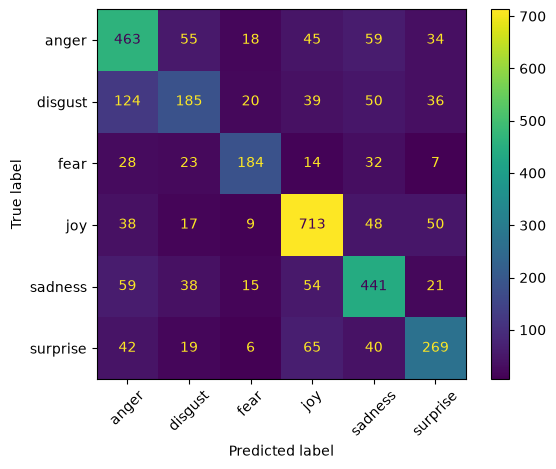

In [14]:
# Final model: fixed simple averages, no weights tuned on the OOF rows (stacking and greedy selection were both worse
# under nested CV with only 3,360 rows).
#   base  = (mean of the 8 transformers + TF-IDF) / 2,   final = 0.5 * base + 0.5 * mean(K3, K4)
import final_blend

base, llm, final = final_blend.blend(runs, 0)
print(f"OOF macro F1  base {macro_f1(base):.4f}  LLMs {macro_f1(llm):.4f}  final {macro_f1(final):.4f}")
print(classification_report(y, final.argmax(1), target_names=classes, digits=3))
ConfusionMatrixDisplay.from_predictions(train["label"], np.array(classes)[final.argmax(1)], labels=classes,
                                        xticks_rotation=45);

In [15]:
# Submission: the same blend on the test probabilities (each run's 5 fold models averaged).
# Kaggle expects the header id,label.
pred = final_blend.blend(runs, 1)[2].argmax(1)
submission = pd.DataFrame({"id": test["post_id"], "label": np.array(classes)[pred]})
assert len(submission) == 1440 and submission["id"].is_unique
out_path = DATA_DIR / "submission_final_K3_K4.csv"
submission.to_csv(out_path, index=False)

# This is the file Kaggle scored: Public 0.6424, Private 0.6643 (7th of 103).
scored = DATA_DIR / "submission_plusN5_K3_K4_w50.csv"
if scored.exists():
    print("identical to the scored submission:", submission.equals(pd.read_csv(scored)))
submission["label"].value_counts()

identical to the scored submission: True


label
joy         399
anger       350
sadness     276
surprise    164
disgust     140
fear        111
Name: count, dtype: int64